# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("/datasets")

In [2]:
# cargar archivos
plans = pd.read_csv(DATA_DIR / "plans.csv")
users = pd.read_csv(DATA_DIR / "users_latam.csv")
usage = pd.read_csv(DATA_DIR / "usage.csv")

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# filas y columnas
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


### 📝 Conclusiones del Paso 1: Carga y exploración

**Qué hice**
  
- Importé `pandas`, `seaborn` y `matplotlib`, y cargué los tres CSV desde `/datasets` en `plans`, `users` y `usage`.
- Revisé las primeras filas (`.head()`), el tamaño (`.shape`) y los tipos y nulos (`.info()`) de cada dataset.

**Estructura de los datos**

| Dataset | Filas | Columnas | Granularidad |
|---|---|---|---|
| `plans` | 2 | 8 | un registro por plan (Basico, Premium) |
| `users` | 4000 | 8 | un registro por cliente |
| `usage` | 40000 | 6 | un registro por **evento** (llamada o mensaje) |

**Claves de unión**
- `users.user_id` ↔ `usage.user_id`
- `users.plan` ↔ `plans.plan_name` (nombres de columna distintos)
- Como `usage` es por evento, hay que **agregarlo por `user_id` antes de unirlo** con `users`, para no duplicar clientes.

**Tipos de datos**
- `reg_date`, `churn_date` (users) y `date` (usage) están como `object`. Hay que convertirlas a fecha (paso 2.3).

**Valores nulos visibles en `.info()`**
- `users.city`: 469 nulos (11,7 %).
- `users.churn_date`: 3534 nulos (88,4 %). Un nulo aquí significa que el cliente **no se ha dado de baja**, no es un error.
- `usage.date`: 50 nulos (0,1 %).
- `usage.duration`: 22076 nulos (55,2 %) y `usage.length`: 17896 nulos (44,7 %). Parecen depender del tipo de evento (llamada o mensaje); se verifica en el paso 3.2.

**Posibles problemas a confirmar en el paso 2**
- `city` contiene `?` y mezcla formatos (`CDMX`, `GDL`, `Medellín`, `Bogotá`).
- `duration` + `length` suman 40028 valores no nulos para 40000 filas, así que al menos 28 eventos tendrían ambos campos informados, lo cual contradice `type`.
- El enunciado anticipa un sentinel `-999` en `age`. `.info()` no lo muestra porque es `int64` sin nulos, y se busca con `.describe()`.
- `plans` incluye `gb_per_month`, pero `usage` no tiene datos de consumo de GB: no se podrá analizar ese uso.

**Siguiente paso:** 2.1 Revisión de valores nulos.

---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para usage
print("Cantidad de valores nulos:")
print(usage.isna().sum())
print("\nProporción de valores nulos (%):")
print((usage.isna().mean() * 100).round(2))

Cantidad de valores nulos:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos (%):
id           0.00
user_id      0.00
type         0.00
date         0.12
duration    55.19
length      44.74
dtype: float64


In [11]:
# cantidad de nulos para users
print("Cantidad de valores nulos:")
print(users.isna().sum())
print("\nProporción de valores nulos (%):")
print((users.isna().mean() * 100).round(2))

Cantidad de valores nulos:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos (%):
user_id        0.00
first_name     0.00
last_name      0.00
age            0.00
city          11.72
reg_date       0.00
plan           0.00
churn_date    88.35
dtype: float64


In [12]:
# 1. ¿Qué valores tiene type? (por si hay variantes: "Call", "sms"...)
usage["type"].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

In [13]:
# 2. % de nulos de duration y length según el tipo de evento
for col in ["duration", "length"]:
    print(f"% de nulos en {col} por type")
    print((usage[col].isna().groupby(usage["type"]).mean() * 100).round(2))
    print()

% de nulos en duration por type
type
call     0.00
text    99.93
Name: duration, dtype: float64

% de nulos en length por type
type
call    99.93
text     0.00
Name: length, dtype: float64



In [14]:
# 3. Recuento absoluto, para ver cuántas filas hay detrás de cada porcentaje
pd.crosstab(usage["type"], usage["duration"].isna(), margins=True)

duration,False,True,All
type,,,
call,17908,0,17908
text,16,22076,22092
All,17924,22076,40000


In [15]:
# 4. Eventos con duration Y length informados a la vez (no debería haber ninguno)
ambos = usage["duration"].notna() & usage["length"].notna()
print(ambos.sum())

28


In [16]:
pd.crosstab(usage["type"], usage["length"].isna())

length,False,True
type,,
call,12,17896
text,22092,0


In [17]:
usage[ambos].sort_values("type")

,id,user_id,type,date,duration,length
12692,12693,12263,call,2024-02-27 10:23:08.374709367,1.80,1490.0
26506,26507,12400,call,2024-04-29 22:37:24.836120902,1.12,1490.0
26587,26588,11241,call,2024-04-30 07:25:13.387834696,1.03,1490.0
20778,20779,11401,call,2024-04-04 00:32:49.969249231,1.01,1490.0
20727,20728,10599,call,2024-04-03 19:00:30.510762768,0.40,1490.0
16910,16911,12099,call,2024-03-17 12:28:18.882472061,3.29,1490.0
25444,25445,10781,call,2024-04-25 03:17:14.935873396,3.57,1490.0
26057,26058,11018,call,2024-04-27 21:51:39.407485186,0.63,1490.0
10614,10615,13855,call,2024-02-18 00:42:33.183829595,0.53,1490.0
5272,5273,11750,call,2024-01-24 20:33:12.649816245,3.78,1490.0


In [18]:
usage[ambos].groupby("type")[["duration", "length"]].agg(["min", "max", "nunique"])

duration                  length                
          min     max nunique     min     max nunique
type                                                 
call      0.4    3.78      12  1490.0  1490.0       1
text    120.0  120.00       1    19.0    89.0      15


**Valores nulos**

- **`users.city` (469, 11,7 %):** hipótesis: errores de captura (se confirma en 2.2, donde también aparece `?`). Acción: dejar como nulo, sin imputar; rellenar con la moda sesgaría la segmentación por país.
- **`users.churn_date` (3534, 88,4 %):** el nulo significa cliente activo, no dato faltante. Acción: conservar la columna y crear `churned`. Eliminarla destruiría el análisis de abandono.
- **`usage.date` (50, 0,12 %):** volumen mínimo. Acción: dejar como nulo; esos eventos siguen contando en los totales y solo quedan fuera de análisis temporales.
- **`usage.duration` y `usage.length`:** dependen de `type` (0 % de nulos en llamadas para `duration`; 0 % en mensajes para `length`). Excepción: 28 eventos (0,07 %) con ambos campos: 12 llamadas con `length = 1490` y 16 mensajes con `duration = 120`, siempre el mismo valor, en clientes y fechas distintos. Parecen valores por defecto, no mediciones. Acción: dejar los nulos estructurales sin imputar; en 3.2 poner a NaN el campo que no corresponde al `type`, sin eliminar filas, para evitar falsos outliers en minutos.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [19]:
# explorar columnas numéricas de users
users[["user_id", "age"]].describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [20]:
print(users["user_id"].nunique(), len(users))   # ¿único?
print((users["age"] < 0).sum())                  # cuántos valores negativos

4000 4000
55


In [21]:
(users["age"] == -999).sum()

55

In [22]:
(users["age"] == -999).sum(), users.loc[users["age"] > 0, "age"].describe()

(55,
 count    3945.000000
 mean       48.137896
 std        17.812830
 min        18.000000
 25%        33.000000
 50%        48.000000
 75%        64.000000
 max        79.000000
 Name: age, dtype: float64)

- La columna `user_id` tiene 4000 valores distintos en 4000 filas: ningún cliente está duplicado. Va de 10000 a 13999, ids consecutivos sin huecos.
- La columna `age` tiene un sentinel: 55 filas (1,4 %) con valor -999, un código de "dato desconocido" y no un error de escritura. Las edades válidas van de 18 a 79 (mediana 48; con el sentinel dentro sale 47). Arrastra la media (33,7) muy por debajo de la mediana y la desviación (123) es imposible. Acción: sustituir por la mediana de las edades válidas (paso 3.1).

In [23]:

# explorar columnas numéricas de usage
usage[["id", "user_id", "duration", "length"]].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


In [24]:
print(usage["id"].nunique(), len(usage))         # ¿id único?
print((usage[["duration", "length"]] <= 0).sum())

40000 40000
duration     15
length      133
dtype: int64


In [25]:
usage[usage["length"] == 0]["type"].value_counts()

text    133
Name: type, dtype: int64


- Las columnas `id` y `user_id`: `id` es único (40000 valores en 40000 filas) y `user_id` va de 10000 a 13999, el mismo rango que `users` (falta confirmar que todos existen allí).
- La columna `duration`: la media (5,2) supera a la mediana (3,5), distribución sesgada a la derecha. El máximo, 120, es el valor constante de los 16 mensajes ya descritos en 2.1. Además 15 llamadas tienen duración 0: a investigar antes de decidir.
- La columna `length`: el máximo, 1490, es el valor constante de las 12 llamadas ya descritas. Además 133 mensajes tienen longitud 0, y un mensaje vacío no debería existir; a investigar.

In [26]:
# explorar columnas categóricas de users
columnas_user = ["city", "plan"]
for col in columnas_user:
    print(users[col].value_counts(dropna=False), "\n")



Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64 

Basico     2595
Premium    1405
Name: plan, dtype: int64 



- La columna `city` no tiene erratas: cada ciudad aparece escrita de una sola forma (México con siglas: CDMX, GDL, MTY; Colombia con nombre completo: Bogotá, Medellín, Cali). El problema son los datos faltantes: 469 NaN + 96 `?` = 565 filas (14,1 %). Acción: `?` → NA (paso 3.1), sin imputar, y crear `country` con un mapeo explícito de ciudades, dejándolo nulo en las 565.
- La columna `plan` solo tiene `Basico` (2595, 64,9 %) y `Premium` (1405, 35,1 %), sin nulos y escritos igual que `plans.plan_name`. Sin problemas: el `merge` no perderá clientes.

In [27]:

# explorar columna categórica de usage
usage["type"].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` solo tiene dos valores, `text` (22092) y `call` (17908), sin nulos ni variantes. Es correcta por sus valores, no por su tipo de dato (`object`).


**Valores inválidos o sentinels**

- **Sentinels confirmados:** `age` (55 filas, 1,4 %, valor -999) y `city` (96 filas, 2,4 %, valor `?`).
- **Valores sospechosos que el enunciado no menciona:** `duration = 0` (15 llamadas), `length = 0` (133 mensajes) y los valores constantes descritos en 2.1 (`length = 1490` en 12 llamadas, `duration = 120` en 16 mensajes).
- **Acciones:** `age`: -999 → mediana de las edades válidas (48). `city`: `?` → NA, sin imputar. Valores constantes → NaN en el campo que no corresponde al `type` (paso 3.2). Ceros: acción provisional, dejarlos y marcarlos; se revisa su peso en los outliers del paso 5.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [28]:

# Convertir a fecha la columna `reg_date` de users
nulos_antes = users["reg_date"].isna().sum()
users["reg_date"] = pd.to_datetime(users["reg_date"], errors="coerce")
print("Nulos antes:", nulos_antes, "| después:", users["reg_date"].isna().sum())

Nulos antes: 0 | después: 0


In [29]:
# Convertir a fecha la columna `date` de usage
nulos_antes = usage["date"].isna().sum()
usage["date"] = pd.to_datetime(usage["date"], errors="coerce")
print("Nulos antes:", nulos_antes, "| después:", usage["date"].isna().sum())

Nulos antes: 50 | después: 50


In [30]:
# Revisar los años presentes en `reg_date` de users
users["reg_date"].dt.year.value_counts().sort_index()


2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, los años presentes son 2022 (1314), 2023 (1316), 2024 (1330) y 2026 (40 filas, 1,0 %). La conversión no genera nulos nuevos (0 antes y después). No hay registros en 2025 y los de 2026 son posteriores al corte de los datos (2024).

In [31]:
# Revisar los años presentes en `date` de usage
usage["date"].dt.year.value_counts().sort_index()


2024.0    39950
Name: date, dtype: int64

In [32]:
fuera = users[users["reg_date"].dt.year > 2024]
print(usage["user_id"].isin(fuera["user_id"]).sum())      # eventos de esos clientes
print(usage["date"].min(), usage["date"].max())           # rango real de usage

374
2024-01-01 00:00:00 2024-06-30 00:00:00


En `date`, todos los eventos con fecha son de 2024 (39950). Los 50 nulos son los mismos de antes de convertir (coinciden con 2.1), así que la conversión no ocultó fechas inválidas. El rango real va del 2024-01-01 al 2024-06-30: seis meses, no el año completo.

- **Fechas fuera de rango**

- **¿Aparecen años imposibles?** Sí, en `reg_date`: 40 clientes (1,0 %) con año 2026, posterior al corte de los datos. En `usage.date` no hay años imposibles.
- **¿Qué haría?** Marcar esas 40 fechas como nulas (paso 3.1), sin eliminar a los clientes ni imputar una fecha: 2026 es imposible porque los datos terminan en 2024 y no hay base para inventar la fecha real. Los 50 nulos de `usage.date` se dejan sin imputar, y el README debe aclarar que el análisis cubre enero-junio de 2024.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [33]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users["age"] != -999, "age"].median()   # solo edades válidas
users["age"] = users["age"].replace(-999, age_mediana)

# Verificar cambios
print(age_mediana, users["age"].dtype)
users["age"].describe()

48.0 float64


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [34]:
# Reemplazar ? por NA en city
users["city"] = users["city"].replace("?", pd.NA)

# Verificar cambios
print(users["city"].isin(["?"]).sum(), users["city"].isna().sum())


0 565


In [35]:
# Marcar fechas fuera de rango como NA para reg_date
users.loc[users["reg_date"].dt.year > 2024, "reg_date"] = pd.NaT

# Verificar cambios
print(users["reg_date"].isna().sum())
users["reg_date"].dt.year.value_counts().sort_index()

40


2022.0    1314
2023.0    1316
2024.0    1330
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [36]:
# Verificación MAR en usage para duration
print(usage["duration"].isna().groupby(usage["type"]).mean().mul(100).round(2))


type
call     0.00
text    99.93
Name: duration, dtype: float64


In [37]:
# Verificación MAR en usage para length
print(usage["length"].isna().groupby(usage["type"]).mean().mul(100).round(2))


type
call    99.93
text     0.00
Name: length, dtype: float64


In [38]:
# Corregir los 28 eventos con un campo que no corresponde a su type
usage.loc[usage["type"] == "text", "duration"] = np.nan
usage.loc[usage["type"] == "call", "length"] = np.nan

# Verificar cambios
print(usage.groupby("type")[["duration", "length"]].count())

      duration  length
type                  
call     17908       0
text         0   22092


**Diagnóstico de nulos en `duration` y `length`:** dependen por completo de `type`, una variable observada, que es lo que define MAR. `duration` es nula en 0 % de las llamadas y en 99,93 % de los mensajes, y `length` al revés. Es además ausencia estructural: un mensaje no tiene duración ni una llamada tiene longitud. Decisión: dejarlos como nulos, sin imputar, porque imputar inventaría minutos para mensajes y sesgaría las medias. Excepción: 28 eventos (12 llamadas con `length = 1490` y 16 mensajes con `duration = 120`) con un valor constante que no es una medición; se ponen a NaN según `type`, sin eliminar filas.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [39]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar informacion por usuario
usage_agg = (
    usage.groupby("user_id")
         .agg({"is_text": "sum", "is_call": "sum", "duration": "sum"})
         .reset_index()
)
usage_agg.head(3)

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [40]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada",
})
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [41]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left", validate="one_to_one")

metricas = ["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
print(user_profile.shape)                         # esperado: (4000, 11)
print(user_profile[metricas].isna().sum())        # clientes sin ningún evento

user_profile[metricas] = user_profile[metricas].fillna(0)   # sin eventos = uso real 0
user_profile = user_profile.astype({"cant_mensajes": int, "cant_llamadas": int})

print(user_profile["cant_llamadas"].sum(), user_profile["cant_mensajes"].sum())   # 17908 y 22092
print(user_profile["cant_minutos_llamada"].sum(), usage["duration"].sum())        # deben coincidir
user_profile.head(5)

(4000, 11)
cant_mensajes           1
cant_llamadas           1
cant_minutos_llamada    1
dtype: int64
17908 22092
91324.9 91324.9


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01


In [42]:
sin_uso = (user_profile["cant_llamadas"] + user_profile["cant_mensajes"] == 0).sum()
print("Clientes sin ningún evento:", sin_uso)

Clientes sin ningún evento: 1


In [43]:
ev = usage.merge(users[["user_id", "reg_date"]], on="user_id", how="left")
antes = ev["date"] < ev["reg_date"]
print(antes.sum(), round(antes.mean() * 100, 1))

10078 25.2


In [44]:
print(antes.groupby(ev["reg_date"].dt.year).mean().mul(100).round(1))

reg_date
2022.0     0.0
2023.0     0.0
2024.0    75.3
dtype: float64


**Coherencia entre tablas:** 10078 eventos (25,2 %) tienen una fecha anterior a la `reg_date` de su cliente. Por año de alta: 2022 0,0 %, 2023 0,0 % y 2024 75,3 %, es decir, el problema se concentra en los clientes dados de alta en 2024. Acción: no eliminar eventos; tratar `reg_date` como poco fiable para medir antigüedad y no usarla para filtrar uso. Se documenta como limitación.

### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [45]:
# Resumen estadístico de las columnas numéricas
cols_num = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
user_profile[cols_num].describe().round(2)


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.00,4000.00,4000.00,4000.00
mean,48.14,5.52,4.48,22.83
std,17.69,2.36,2.15,16.59
min,18.00,0.00,0.00,0.00
25%,33.00,4.00,3.00,11.09
50%,48.00,5.00,4.00,19.74
75%,63.00,7.00,6.00,31.18
max,79.00,17.00,15.00,155.69


In [46]:
# Distribución porcentual del tipo de plan
(user_profile["plan"].value_counts(normalize=True) * 100).round(2)


Basico     64.88
Premium    35.12
Name: plan, dtype: float64

**Resumen estadístico (enero-junio 2024, 4000 clientes)**
- `age`: media 48,1 ≈ mediana 48; rango 18-79 con cuartiles equidistantes (33, 48, 63): distribución casi uniforme. Las 55 edades imputadas con 48 añadirán un pico artificial en ese valor.
- `cant_mensajes`: media 5,5 frente a mediana 5; el máximo (17) está muy por encima del percentil 75 (7), posibles outliers por la derecha (se confirma en el paso 5).
- `cant_llamadas`: media 4,5 frente a mediana 4; máximo 15 frente a percentil 75 de 6, también con posibles outliers por la derecha.
- `cant_minutos_llamada`: media 22,8 > mediana 19,7: sesgo a la derecha; máximo 155,7, casi cinco veces el percentil 75 (31,2): valores extremos probables, a revisar en el paso 5.
- `plan`: Basico 64,88 % y Premium 35,12 %: casi dos de cada tres clientes están en el plan básico.

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

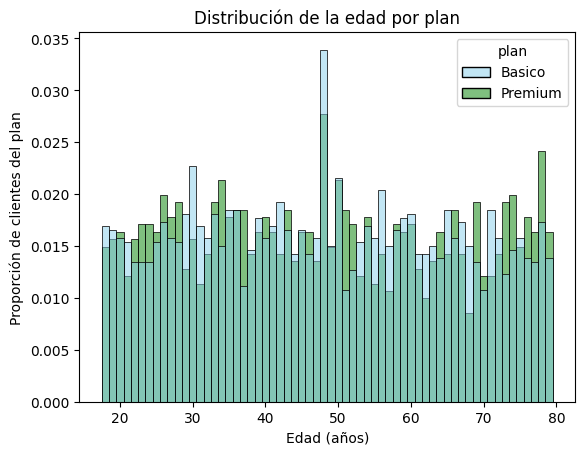

In [47]:

# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x="age", hue="plan",
             hue_order=["Basico", "Premium"], palette=["skyblue", "green"],
             discrete=True, stat="probability", common_norm=False)
plt.title("Distribución de la edad por plan")
plt.xlabel("Edad (años)")
plt.ylabel("Proporción de clientes del plan")
plt.show()

In [48]:
user_profile.groupby("plan")["age"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
plan,,,,,,,,
Basico,2595.0,48.0,17.5,18.0,33.0,48.0,63.0,79.0
Premium,1405.0,48.3,18.0,18.0,33.0,48.0,64.0,79.0



💡 Insights:
- Distribución aproximadamente **uniforme** entre 18 y 79 años (≈1,6 % de los clientes de cada plan por cada edad), sin forma de campana ni sesgo; media y mediana coinciden (≈48).
- Ambos planes siguen el mismo patrón: a simple vista no hay un tramo de edad donde Premium pese más que Basico. Las diferencias entre barras parecen ruido, y las de Premium fluctúan más porque tiene menos clientes (1405 frente a 2595).
- El **pico en 48 años** (≈3,4 % en Basico y ≈2,8 % en Premium) es un artefacto de la imputación: las 55 edades `-999` se sustituyeron por la mediana en el paso 3.1. No representa una concentración real de clientes de esa edad.


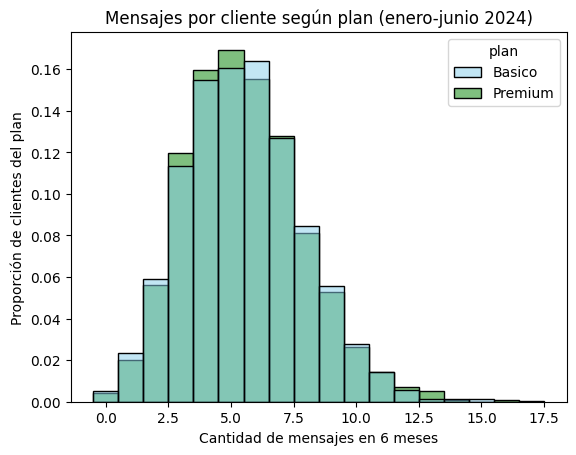

In [49]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x="cant_mensajes", hue="plan",
             hue_order=["Basico", "Premium"], palette=["skyblue", "green"],
             discrete=True, stat="probability", common_norm=False)
plt.title("Mensajes por cliente según plan (enero-junio 2024)")
plt.xlabel("Cantidad de mensajes en 6 meses")
plt.ylabel("Proporción de clientes del plan")
plt.show()


💡 Insights (cant_mensajes):
- Distribución casi simétrica con ligera cola a la derecha, centrada en 5-6 mensajes (≈16-17 % de los clientes en cada valor) y rango 0-17. Media (5,5) y mediana (5) casi coinciden.
- Por plan: prácticamente idénticos (media 5,53 en Basico y 5,52 en Premium; mediana 5 en ambos). El plan no condiciona el volumen de mensajes.
- La varianza (≈5,6) es casi igual a la media (5,5), el patrón típico de un conteo aleatorio, sin indicios de un subgrupo de usuarios intensivos.

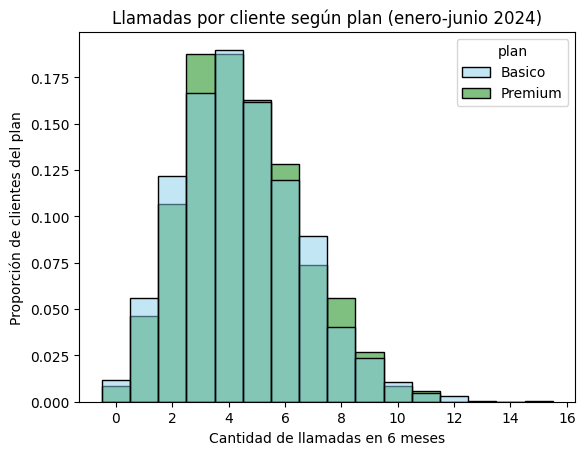

In [50]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x="cant_llamadas", hue="plan",
             hue_order=["Basico", "Premium"], palette=["skyblue", "green"],
             discrete=True, stat="probability", common_norm=False)
plt.title("Llamadas por cliente según plan (enero-junio 2024)")
plt.xlabel("Cantidad de llamadas en 6 meses")
plt.ylabel("Proporción de clientes del plan")
plt.show()



💡 Insights (cant_llamadas):
- Distribución casi simétrica con ligera cola a la derecha, con la moda en 4-5 llamadas (≈19 % de los clientes) y rango 0-15.
- Por plan: muy similares (media 4,45 en Basico y 4,52 en Premium; mediana 4 en ambos). Hay diferencias puntuales (algo más de Basico en 2 llamadas y de Premium en 4 y 8) pero sin un desplazamiento global de la distribución.

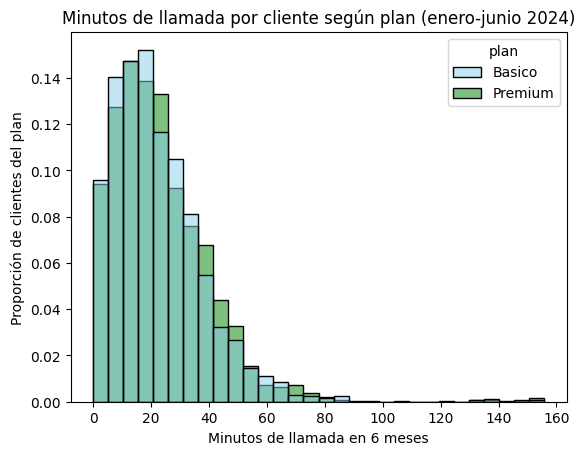

In [51]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x="cant_minutos_llamada", hue="plan",
             hue_order=["Basico", "Premium"], palette=["skyblue", "green"],
             bins=30, stat="probability", common_norm=False)
plt.title("Minutos de llamada por cliente según plan (enero-junio 2024)")
plt.xlabel("Minutos de llamada en 6 meses")
plt.ylabel("Proporción de clientes del plan")
plt.show()


In [52]:
user_profile.groupby("plan")[["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]].agg(["mean", "median"]).round(2)

cant_mensajes        cant_llamadas        cant_minutos_llamada       
                 mean median          mean median                 mean median
plan                                                                         
Basico           5.53      5          4.45      4                22.57  19.51
Premium          5.52      5          4.52      4                23.31  20.30


💡 Insights (cant_minutos_llamada):
- Fuerte sesgo a la derecha: la mayoría acumula entre ~5 y 30 minutos en seis meses, con una cola larga hasta ~160. La media (22,6-23,3) es mayor que la mediana (19,5-20,3).
- Por plan: Premium tiene solo ~0,7 minutos más de media (23,31 frente a 22,57, +3 %), una diferencia pequeña frente a la dispersión (desviación ≈ 16,6). No hay evidencia de que los clientes Premium hablen más.
- Los valores extremos de la cola (hasta ~156 minutos) se evalúan como posibles outliers en 5.2.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

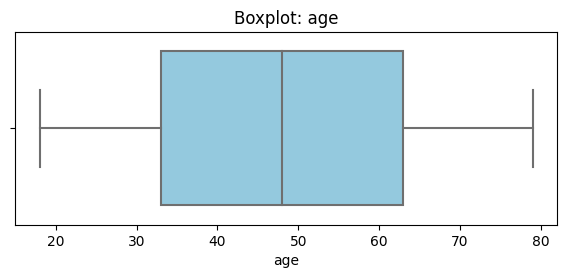

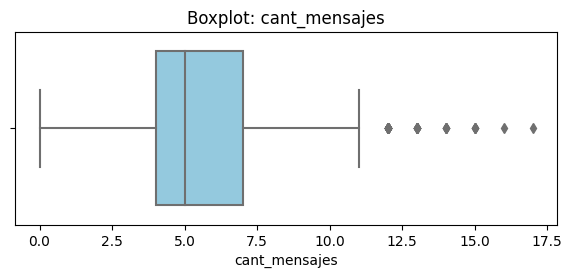

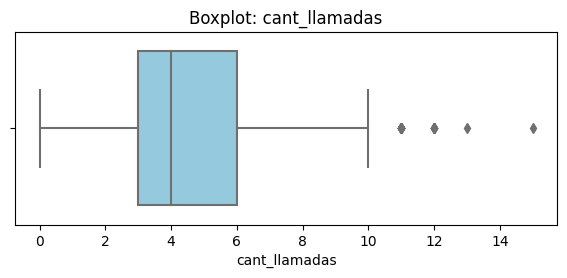

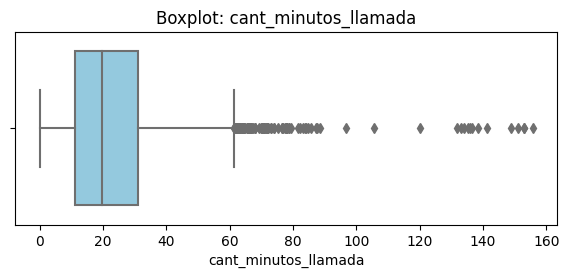

In [53]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(7, 2.5))
    sns.boxplot(x=user_profile[col], color="skyblue")
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()


**Insights – Boxplots y outliers (IQR)**

Las tres variables (`cant_mensajes`, `cant_llamadas`, `cant_minutos_llamada`) tienen la caja pegada a valores bajos y una cola larga a la derecha: distribución asimétrica, con la mayoría de clientes en uso bajo y unos pocos en uso muy alto.

Criterio: límite superior = Q3 + 1,5·IQR. No calculo límite inferior porque saldría negativo y el mínimo posible es 0.

| Variable | Límite superior | Outliers | % de clientes |

| `cant_mensajes` | 11,50 | 46 | 1,1 % |
| `cant_llamadas` | 10,50 | 30 | 0,8 % |
| `cant_minutos_llamada` | 61,32 | 96 | 2,4 % |

- **Mensajes y llamadas:** menos del 1,2 % de clientes supera el límite, así que el comportamiento típico está bien capturado.
- **Minutos:** es la variable con más outliers (96 clientes, 2,4 %). Los 10 mayores tienen entre 4 y 7 llamadas, en línea con el cliente típico, pero 19-38 min por llamada frente a unos 5 de media global. El extremo se debe a llamadas más largas, no a más llamadas, y aparece en ambos planes (7 Basico y 3 Premium en el top 10).

In [54]:

# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1, q3 = user_profile[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_sup = q3 + 1.5 * iqr
    n_out = (user_profile[col] > lim_sup).sum()
    print(f"{col}: Q1={q1:.2f}, Q3={q3:.2f}, límite superior={lim_sup:.2f}, "
          f"máximo={user_profile[col].max():.2f}, outliers={n_out} ({n_out / len(user_profile) * 100:.1f} %)")



cant_mensajes: Q1=4.00, Q3=7.00, límite superior=11.50, máximo=17.00, outliers=46 (1.1 %)
cant_llamadas: Q1=3.00, Q3=6.00, límite superior=10.50, máximo=15.00, outliers=30 (0.8 %)
cant_minutos_llamada: Q1=11.09, Q3=31.18, límite superior=61.32, máximo=155.69, outliers=96 (2.4 %)


In [55]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,22.831225
std,2.359738,2.145139,16.592068
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.087500
50%,5.000000,4.000000,19.735000
75%,7.000000,6.000000,31.182500
max,17.000000,15.000000,155.690000


In [56]:
(user_profile
 .assign(min_por_llamada=user_profile["cant_minutos_llamada"] / user_profile["cant_llamadas"].replace(0, np.nan))
 .nlargest(10, "cant_minutos_llamada")
 [["user_id", "plan", "cant_llamadas", "cant_minutos_llamada", "min_por_llamada"]]
 .round(2))

,user_id,plan,cant_llamadas,cant_minutos_llamada,min_por_llamada
3953,13953,Basico,7,155.69,22.24
534,10534,Premium,4,153.06,38.26
585,10585,Premium,5,153.02,30.60
349,10349,Basico,7,150.92,21.56
216,10216,Premium,6,148.76,24.79
2472,12472,Basico,7,141.37,20.20
3187,13187,Basico,5,138.41,27.68
1589,11589,Premium,4,136.55,34.14
3927,13927,Basico,4,135.96,33.99
1304,11304,Basico,7,135.36,19.34


  **Decisión sobre los outliers: se mantienen**

Un outlier estadístico no es un error. Los clasifico por causa:

- **Mensajes y llamadas:** son recuentos de eventos reales, sin valores imposibles. Corresponden a clientes de uso intensivo.
- **Minutos:** el exceso viene de llamadas más largas, no de más llamadas (4-7 llamadas con 19-38 min cada una). No se ha detectado un error evidente, pero la causa no está confirmada: puede ser comportamiento real o duraciones anómalas.
- **Edad:** sin outliers. Los bigotes cubren de unos 18 a unos 79 años y el rango es plausible.
- **Eliminarlos sesgaría el análisis:** quitaría justo a los clientes de comportamiento más diferenciado.

**Consecuencias:**
- Al comparar planes usaré la **mediana** junto a la media, porque la media se infla con los extremos.
- Los extremos en mensajes y llamadas caerán en el grupo "Alto uso". Los extremos en minutos **no** tienen por qué hacerlo, porque la segmentación usa recuentos.
- Los 96 clientes extremos en minutos quedan **marcados para revisión** con negocio: confirmar si las llamadas largas son legítimas.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [57]:
# Crear columna grupo_uso
condiciones = [
    (user_profile["cant_llamadas"] < 5)  & (user_profile["cant_mensajes"] < 5),
    (user_profile["cant_llamadas"] < 10) & (user_profile["cant_mensajes"] < 10),
]
user_profile["grupo_uso"] = np.select(condiciones, ["Bajo uso", "Uso medio"], default="Alto uso")


In [58]:
user_profile.groupby("grupo_uso")[["cant_llamadas", "cant_mensajes"]].agg(["min", "max"])


cant_llamadas     cant_mensajes    
                    min max           min max
grupo_uso                                    
Alto uso              0  15             0  17
Bajo uso              0   4             0   4
Uso medio             0   9             0   9

In [59]:
# verificar cambios
user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [60]:
# Crear columna grupo_edad
condiciones = [user_profile["age"] < 30, user_profile["age"] < 60]
user_profile["grupo_edad"] = np.select(condiciones, ["Joven", "Adulto"], default="Adulto Mayor")


In [61]:

# verificar cambios
user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

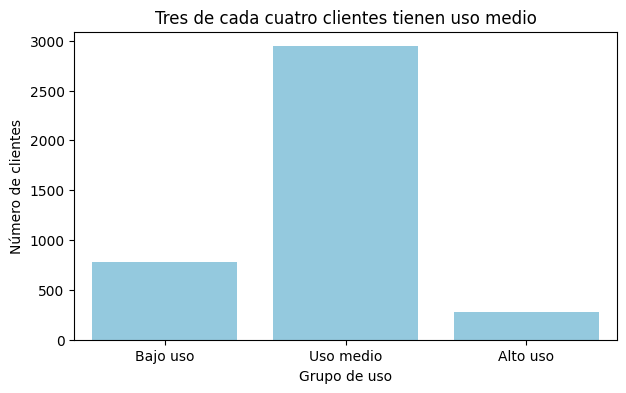

In [62]:


plt.figure(figsize=(7, 4))
sns.countplot(data=user_profile, x="grupo_uso",
              order=["Bajo uso", "Uso medio", "Alto uso"], color="skyblue")
plt.title("Tres de cada cuatro clientes tienen uso medio")   # <- cambiado
plt.xlabel("Grupo de uso")
plt.ylabel("Número de clientes")
plt.show()

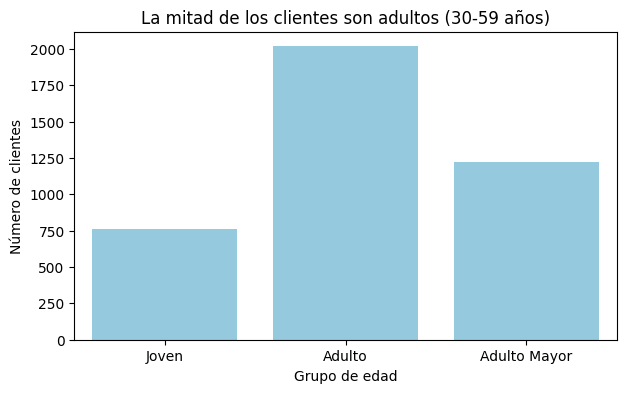

In [63]:
plt.figure(figsize=(7, 4))
sns.countplot(data=user_profile, x="grupo_edad",
              order=["Joven", "Adulto", "Adulto Mayor"], color="skyblue")
plt.title("La mitad de los clientes son adultos (30-59 años)")   # <- cambiado
plt.xlabel("Grupo de edad")
plt.ylabel("Número de clientes")
plt.show()


In [64]:
user_profile["grupo_uso"].value_counts(normalize=True).mul(100).round(1)
user_profile["grupo_edad"].value_counts(normalize=True).mul(100).round(1)

Adulto          50.4
Adulto Mayor    30.6
Joven           19.0
Name: grupo_edad, dtype: float64

In [65]:
pd.crosstab(user_profile["plan"], user_profile["grupo_uso"], normalize="index").mul(100).round(1)

grupo_uso,Alto uso,Bajo uso,Uso medio
plan,,,
Basico,7.1,19.8,73.1
Premium,6.6,18.9,74.4


**Insights – Segmentación**

**Por uso:** la gran mayoría de clientes (casi 3 de cada 4) es de **uso medio**; el **bajo uso** ronda uno de cada cinco y el **alto uso** es una minoría (menos del 10 %). Las reglas se verificaron con mínimos y máximos por grupo. El grupo "Alto uso" incluye perfiles distintos (mucho mensaje, muchas llamadas o ambos), porque basta superar 9 en una de las dos variables.

**Por edad:** la mitad de los clientes son **adultos** (50,4 %), el 30,6 % **adultos mayores** y solo el 19,0 % **jóvenes**. La base de clientes es madura.

**Limitación:** los 55 clientes con edad imputada (1,4 %) están clasificados con un valor aproximado.
**Por plan:** la distribución de uso es prácticamente idéntica en Basico y Premium (alto uso 7,1 % frente a 6,6 %), así que el plan no explica el nivel de consumo.


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

In [66]:
pd.crosstab(user_profile["grupo_edad"], user_profile["grupo_uso"], normalize="index").mul(100).round(1)

grupo_uso,Alto uso,Bajo uso,Uso medio
grupo_edad,,,
Adulto,7.6,18.1,74.3
Adulto Mayor,6.1,21.0,72.9
Joven,6.7,20.7,72.6



### ⚠️ Problemas detectados en los datos

- **`age`:** 55 clientes (1,4 %) con el valor centinela -999. Se sustituyó por la mediana de las edades válidas.
- **`city`:** 565 clientes (14,1 %) sin ciudad válida: 469 nulos y 96 con "?". El "?" se convirtió en nulo y no se imputó (no hay base para inventar una ciudad).
- **`reg_date`:** 40 fechas (1,0 %) posteriores a 2024, imposibles. Se marcaron como nulas.
- **Incoherencia entre tablas:** el 25,2 % de los eventos de uso (10.078) tiene fecha anterior al registro del cliente, concentrado en los dados de alta en 2024. La fecha de registro es poco fiable y no se usó como base de conclusiones.
- **`usage`:** 50 fechas nulas (0,12 %) y 28 eventos anómalos (0,07 %). Los nulos de `duration` y `length` son estructurales (duración solo en llamadas, longitud solo en mensajes), no errores.
- **Cobertura:** 1 cliente (0,03 %) sin ningún evento; se rellenó con 0.
- **El nivel de uso es similar en los tres grupos de edad:** no se observan diferencias apreciables, así que la edad no sirve por sí sola para predecir cuánto consume un cliente ni para diseñar planes.
### 🔍 Segmentos por Edad

- La base es madura: **50,4 % adultos (30-59)**, **30,6 % adultos mayores (60+)** y solo **19,0 % jóvenes (<30)**.
- Más de 8 de cada 10 clientes tienen 30 años o más; el producto no está captando al público joven.

### 📊 Segmentos por Nivel de Uso

- **Uso medio ≈ 74 %**, **bajo uso ≈ 19 %**, **alto uso ≈ 7 %**.
- La distribución es casi idéntica en ambos planes (alto uso: 7,1 % en Basico frente a 6,6 % en Premium).
- El uso es muy bajo frente a lo contratado. En promedio, un cliente envía ≈ 0,9 mensajes y hace ≈ 3,8 minutos de llamada **al mes** (los datos cubren seis meses), frente a los 100 mensajes y 100 minutos del plan Basico. El cliente con más minutos llega a ≈ 26 al mes. *(Supone que el registro de uso está completo y que la duración está en minutos.)*

➡️ **Esto sugiere que** el plan contratado no explica cuánto se consume: Premium (25 USD) no se usa más que Basico (12 USD), y casi nadie se acerca a los límites de ninguno de los dos.

### ⭐ Segmentos más valiosos

- **Premium:** paga 13 USD más al mes con el mismo uso que Basico. Es el segmento más rentable, pero también el más expuesto a darse de baja o bajar de plan si el cliente nota que no usa lo que paga.
- **Alto uso (≈ 7 %):** es el más comprometido con el servicio; prioritario para retención y venta de ampliaciones.
- **Adultos (50,4 %):** el mayor volumen de clientes y la base natural del negocio.

### 🚨 Patrones de uso extremo (outliers)

- **Mensajes:** 46 clientes (1,1 %); **llamadas:** 30 (0,8 %); **minutos:** 96 (2,4 %).
- En minutos, el exceso viene de **llamadas más largas, no de más llamadas**: el top 10 tiene 4-7 llamadas, pero 19-38 min por llamada frente a ≈ 5 de media global. Aparece en ambos planes.
- Se mantuvieron en el análisis (no son errores evidentes). Los 96 de minutos quedan **pendientes de validar** con negocio, por si hay duraciones anómalas.

### 💡 Recomendaciones

1. **Revisar el valor de Premium:** con el mismo uso que Basico y límites sin consumir, su precio no se justifica por consumo. Replantearlo con beneficios distintos al volumen, o ajustar su precio.
2. **Plan de entrada más ajustado:** el 74 % usa una fracción mínima de Basico. Un plan más barato y con menos volumen sería más competitivo sin perder margen real.
3. **Complemento de minutos** para el grupo de llamadas largas, **después** de validar que esas duraciones son reales.
4. **Retención del alto uso (≈ 7 %):** programa de fidelización antes de que se vayan.
5. **Calidad de datos en origen:** validar edad y ciudad al registrar (sin -999 ni "?") y corregir la captura de `reg_date`.
6. **Siguiente análisis:** cruzar segmentos con `churn_date` para saber qué grupo se da de baja más y priorizar con dinero, no con intuición.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`